In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import sys
sys.path.append("/home/dev/pose")

from pose.config import get_cfg_defaults

In [3]:
%matplotlib inline
import math
import torch

from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import InterpolationMode
from torchvision.transforms.v2 import ToPILImage
from torchvision.transforms.v2.functional import affine

from torchvision.utils import draw_bounding_boxes
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

cfg = get_cfg_defaults()

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [4]:
from pose.data.dataset import CocoDataset

In [5]:
dataset = CocoDataset(cfg, is_train=False, transform=None)

2025-01-17 23:53:48.906 | INFO     | pose.data.dataset:_init_coco_info:128 - Keypoints idx2name: dict_items([(0, 'nose'), (1, 'L-eye'), (2, 'R-eye'), (3, 'L-ear'), (4, 'R-ear'), (5, 'L-shder'), (6, 'R-shder'), (7, 'L-elb'), (8, 'R-elb'), (9, 'L-wrst'), (10, 'R-wrst'), (11, 'L-hip'), (12, 'R-hip'), (13, 'L-knee'), (14, 'R-knee'), (15, 'L-ankl'), (16, 'R-ankl')])
2025-01-17 23:53:48.954 | INFO     | pose.data.dataset:__init__:52 - Annotation fname: /home/dev/data/coco/annotations/person_keypoints_val2017.json
2025-01-17 23:53:48.954 | INFO     | pose.data.dataset:__init__:54 - Image file director: /home/dev/data/coco/images/val2017/
2025-01-17 23:53:48.955 | INFO     | pose.data.dataset:__init__:57 - NN input size(height, width): [256, 192]
2025-01-17 23:53:48.955 | INFO     | pose.data.dataset:__init__:80 - Data augmentation: False
2025-01-17 23:53:48.958 | INFO     | pose.data.dataset:__init__:88 - Num images: 5,000
2025-01-17 23:53:48.958 | INFO     | pose.data.dataset:__init__:91 - N

2025-01-17 23:54:20.953 | DEBUG    | pose.data.dataset:__getitem__:167 - rotate: 0.00, scale: 1.25
2025-01-17 23:54:20.956 | DEBUG    | pose.data.transforms:crop_and_resize_image:42 - original image size(c,h,w): torch.Size([3, 480, 640])
2025-01-17 23:54:20.957 | DEBUG    | pose.data.transforms:crop_and_resize_image:43 - original box size(h,w): 129, 119
2025-01-17 23:54:20.957 | DEBUG    | pose.data.transforms:crop_and_resize_image:44 - bbox center: [409, 279]
2025-01-17 23:54:20.957 | DEBUG    | pose.data.transforms:crop_and_resize_image:48 - bh=min(161.25, 142, 818)
2025-01-17 23:54:20.958 | DEBUG    | pose.data.transforms:crop_and_resize_image:50 - bw=min(148.75, 722, 558)
2025-01-17 23:54:20.958 | DEBUG    | pose.data.transforms:crop_and_resize_image:62 - new bbox: y(338) x(226) h(142) w(106)
2025-01-17 23:54:20.959 | DEBUG    | pose.data.transforms:crop_and_resize_image:65 - expected output size: [256, 192]
2025-01-17 23:54:20.959 | DEBUG    | pose.data.transforms:crop_and_resize_

idx: 1701
Num keypoints: 12


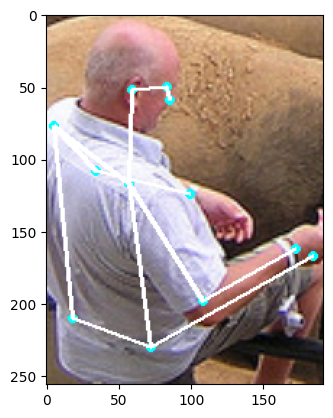

In [16]:
idx = random.randint(0, len(dataset)-1)
# idx = 4574
print(f"idx: {idx}")
nn_input, target_y, target_x, target_weight, extra_info = dataset[idx]
image = extra_info["image"]
_kp = extra_info["keypoints"]
kp = torch.Tensor(17,2)
kp[:,0] = _kp[:,1]
kp[:,1] = _kp[:,0]
kp = kp.reshape(1,17,2)
vis = extra_info["vis"].reshape(1,17)

print(f"Num keypoints: {(vis > 0).sum()}")

image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()

index: 1701
bbox: y(345) x(220) h(129) w(119)


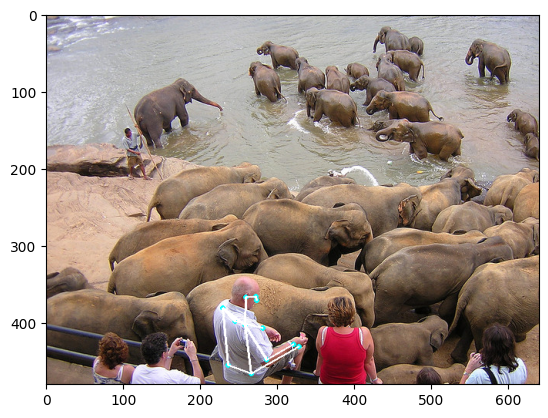

In [17]:
print(f"index: {idx}")
sample = dataset.get_sample(idx)
print("bbox:", sample.bbox)
image_meta = dataset.get_image_meta(sample.image_id)
image_path = image_meta.fpath
image = read_image(image_path)
if image.shape[0] == 1:
    image = image.repeat(3, 1, 1)
keypoints = sample.keypoints
kp = keypoints.get_kps(coord="xy").reshape(1,17,2)
vis = keypoints.get_vis().reshape(1,17)
image = draw_keypoints(image, kp, connectivity=connectivity, colors=COLOR_CYAN, radius=3, visibility=vis)
image = to_pil(image)
plt.imshow(image)
plt.show()